In [1]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

df.head()

Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data Types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows: 5268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
print("Missing Customer IDs:", df["CustomerID"].isnull().sum())

print("Cancelled Invoices:",
      df["InvoiceNo"].astype(str).str.startswith("C").sum())

print("Negative Quantities:", (df["Quantity"] <= 0).sum())

print("Non-positive Prices:", (df["UnitPrice"] <= 0).sum())


Missing Customer IDs: 135080
Cancelled Invoices: 9288
Negative Quantities: 10624
Non-positive Prices: 2517


In [5]:
df = df.dropna(subset=["CustomerID"]).copy()

df = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

df["CustomerID"] = df["CustomerID"].astype(int)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print("Cleaned Dataset Shape:", df.shape)
df.head()

Cleaned Dataset Shape: (397884, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [6]:
# Latest invoice date
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Customer-wise RFM analysis
rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalPrice": "sum"
})

# Rename columns
rfm.columns = ["Recency", "Frequency", "Monetary"]

# Display results
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [7]:
# RFM descriptive statistics
print("RFM Descriptive Statistics:")
display(rfm.describe().round(2))

# Average purchase value per customer
average_purchase_value = (
    df.groupby("CustomerID")["TotalPrice"].mean().mean()
)

print("Average Purchase Value per Customer: £",
      round(average_purchase_value, 2))

# Average purchase frequency
print("Average Purchase Frequency:",
      round(rfm["Frequency"].mean(), 2), "orders")

# Average customer spending (CLV proxy)
print("Average Customer Spending (CLV Proxy): £",
      round(rfm["Monetary"].mean(), 2))

RFM Descriptive Statistics:


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2054.27
std,100.01,7.70,8989.23
min,1.00,1.00,3.75
25%,18.00,1.00,307.41
50%,51.00,2.00,674.48
75%,142.00,5.00,1661.74
max,374.00,209.00,280206.02


Average Purchase Value per Customer: £ 68.35
Average Purchase Frequency: 4.27 orders
Average Customer Spending (CLV Proxy): £ 2054.27


In [8]:
from sklearn.preprocessing import StandardScaler

# Select RFM features
X = rfm[["Recency", "Frequency", "Monetary"]]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert scaled data into a DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

# Display the standardized data
X_scaled_df.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,2.334574,-0.425097,8.358668
12347,-0.905340,0.354417,0.250966
12348,-0.175360,-0.035340,-0.028596
12349,-0.735345,-0.425097,-0.033012
12350,2.174578,-0.425097,-0.191347


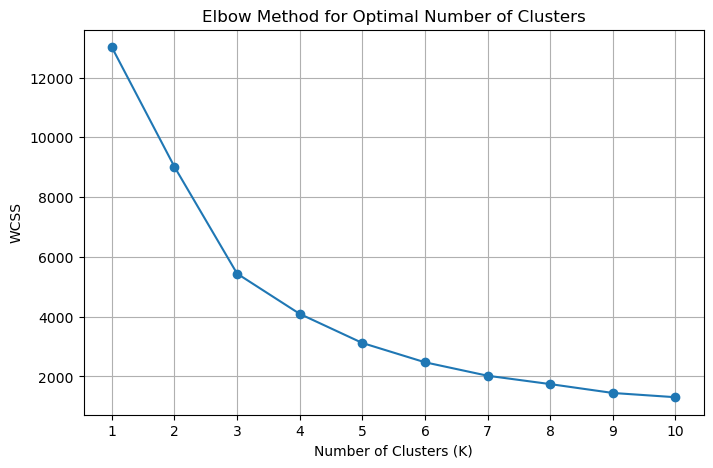

In [9]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Calculate WCSS for different numbers of clusters
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled_df)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [10]:
from sklearn.cluster import KMeans

# Create K-Means model with 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit model and assign cluster labels
rfm["Cluster"] = kmeans.fit_predict(X_scaled_df)

# Display customer segmentation
print("Customer Segmentation Completed!")
print("\nCustomers in Each Cluster:")
print(rfm["Cluster"].value_counts().sort_index())

# Show first 5 rows
rfm.head()

Customer Segmentation Completed!

Customers in Each Cluster:
Cluster
0    1082
1    3230
2      26
Name: count, dtype: int64


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,0
12347,2,7,4310.00,1
12348,75,4,1797.24,1
12349,19,1,1757.55,1
12350,310,1,334.40,0


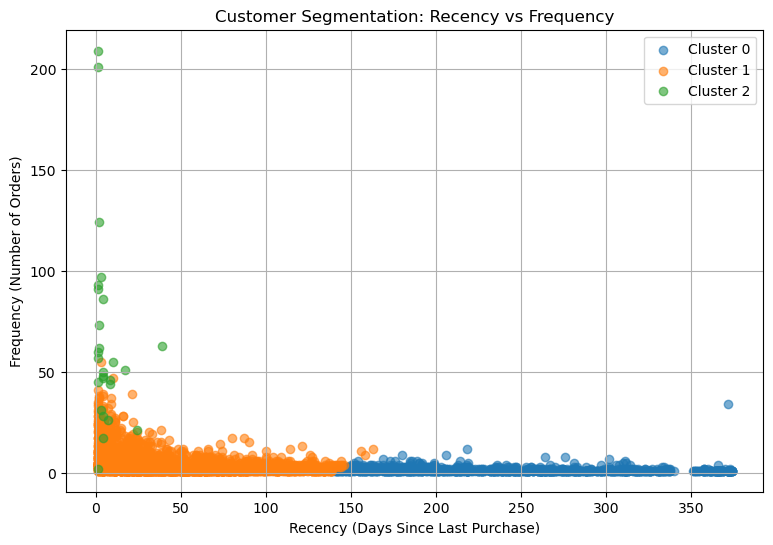

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for cluster in sorted(rfm["Cluster"].unique()):
    cluster_data = rfm[rfm["Cluster"] == cluster]

    plt.scatter(
        cluster_data["Recency"],
        cluster_data["Frequency"],
        label=f"Cluster {cluster}",
        alpha=0.6
    )

plt.title("Customer Segmentation: Recency vs Frequency")
plt.xlabel("Recency (Days Since Last Purchase)")
plt.ylabel("Frequency (Number of Orders)")
plt.legend()
plt.grid(True)
plt.show()

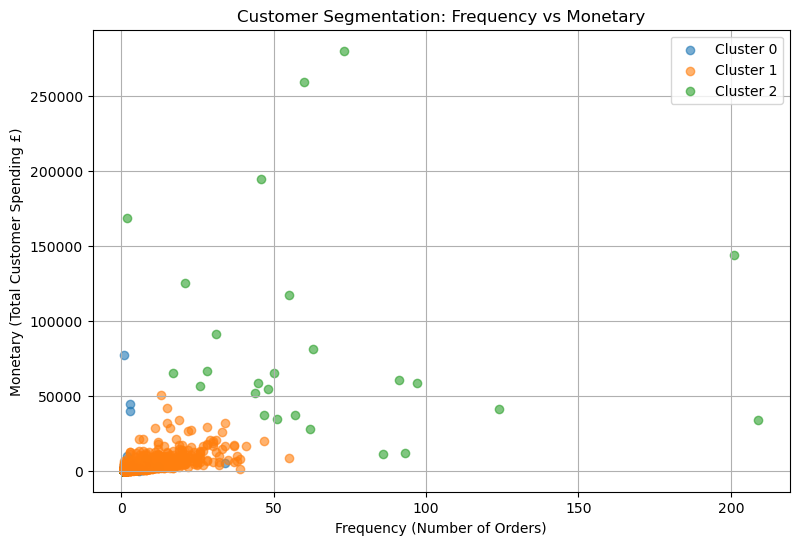

In [12]:
plt.figure(figsize=(9, 6))

for cluster in sorted(rfm["Cluster"].unique()):
    cluster_data = rfm[rfm["Cluster"] == cluster]

    plt.scatter(
        cluster_data["Frequency"],
        cluster_data["Monetary"],
        label=f"Cluster {cluster}",
        alpha=0.6
    )

plt.title("Customer Segmentation: Frequency vs Monetary")
plt.xlabel("Frequency (Number of Orders)")
plt.ylabel("Monetary (Total Customer Spending £)")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
# Calculate average RFM values for each cluster
cluster_profile = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)

print("Customer Cluster Profiles:")
display(cluster_profile)

Customer Cluster Profiles:


,Recency,Frequency,Monetary
Cluster,,,
0,247.11,1.58,631.42
1,41.45,4.67,1855.94
2,6.04,66.42,85904.35


Number of Customers in Each Cluster:


Cluster
0    1082
1    3230
2      26
Name: count, dtype: int64

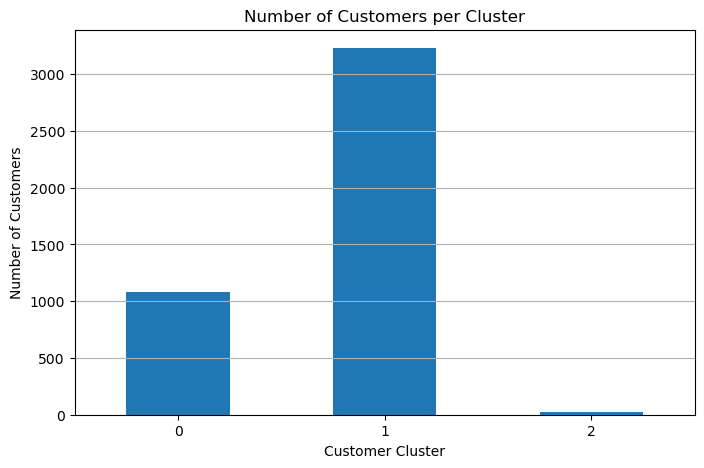

In [14]:
# Count customers in each cluster
cluster_counts = rfm["Cluster"].value_counts().sort_index()

print("Number of Customers in Each Cluster:")
display(cluster_counts)

# Bar chart
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
cluster_counts.plot(kind="bar")
plt.title("Number of Customers per Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [15]:
for cluster, row in cluster_profile.iterrows():
    print(f"\nCluster {cluster}")
    print(f"Average Recency: {row['Recency']:.1f} days")
    print(f"Average Frequency: {row['Frequency']:.1f} orders")
    print(f"Average Monetary: £{row['Monetary']:.2f}")

    if (row["Recency"] <= cluster_profile["Recency"].median()
        and row["Frequency"] >= cluster_profile["Frequency"].median()
        and row["Monetary"] >= cluster_profile["Monetary"].median()):
        print("Customer Type: Loyal / High-Value Customers")
        print("Recommendation: Give loyalty rewards and exclusive offers.")

    elif row["Recency"] > cluster_profile["Recency"].median():
        print("Customer Type: At-Risk / Inactive Customers")
        print("Recommendation: Send win-back emails and special discounts.")

    else:
        print("Customer Type: Regular / Potential Customers")
        print("Recommendation: Offer product recommendations and bundle deals.")


Cluster 0
Average Recency: 247.1 days
Average Frequency: 1.6 orders
Average Monetary: £631.42
Customer Type: At-Risk / Inactive Customers
Recommendation: Send win-back emails and special discounts.

Cluster 1
Average Recency: 41.5 days
Average Frequency: 4.7 orders
Average Monetary: £1855.94
Customer Type: Loyal / High-Value Customers
Recommendation: Give loyalty rewards and exclusive offers.

Cluster 2
Average Recency: 6.0 days
Average Frequency: 66.4 orders
Average Monetary: £85904.35
Customer Type: Loyal / High-Value Customers
Recommendation: Give loyalty rewards and exclusive offers.


## Conclusion – Customer Segmentation Analysis

- Cleaned the Online Retail dataset by removing missing customer IDs, cancelled invoices, and invalid transactions.
- Calculated Recency, Frequency, and Monetary (RFM) features to understand customer purchasing behaviour.
- Standardized the RFM features using StandardScaler.
- Applied the Elbow Method to help select the number of clusters.
- Used K-Means clustering to segment customers into three groups.
- Visualized customer segments using scatter plots and a bar chart.
- Developed marketing recommendations based on customers’ recency, purchase frequency, and total spending.

**Business Impact:** Customer segmentation can help businesses identify valuable customers, improve customer retention, and design targeted marketing campaigns.